# 🏦 Pipeline Preditivo de Risco de Crédito

**Curso:** Machine Learning e Visão Computacional [T5] — SENAI/SC
**Autor:** Waldinei Lameira Rosa
**Base escolhida:** Opção A — Risco de Crédito (Setor Financeiro)

---

## Objetivo de negócio

Prever a probabilidade de um cliente se tornar **inadimplente** (`loan_status = 1`) em comparação aos bons pagadores (`loan_status = 0`), comparando dois algoritmos clássicos — **KNN** e **Árvore de Decisão** — e recomendando o mais adequado para produção com base no **impacto financeiro** dos erros:

- **Falso Positivo (FP):** bom pagador rotulado como "risco de calote" → o banco nega crédito e perde a receita de juros.
- **Falso Negativo (FN):** mau pagador rotulado como "seguro" → o banco concede crédito e pode perder o capital emprestado.

## Roteiro do notebook

| Fase | Conteúdo |
|---|---|
| 0 | Configuração do ambiente e carregamento da base |
| 1 | Análise Exploratória de Dados (EDA) |
| 2 | Tratamento e limpeza (duplicados, nulos, outliers) |
| 3 | Feature Engineering — `comprometimento_renda` |
| 4 | Encoding, split estratificado, balanceamento e escalonamento seguro |
| 5 | Modelagem e diagnóstico de overfitting (KNN × Árvore) |
| 6 | Avaliação e veredito de negócio |

---
# Fase 0 — Configuração do ambiente

**Decisões técnicas desta fase:**

1. **Importações centralizadas no topo:** todas as bibliotecas usadas no pipeline são importadas em uma única célula. Se alguma estiver faltando no `.venv`, o erro aparece logo no início, e não no meio da modelagem.
2. **Semente aleatória fixa (`SEED = 42`):** o split treino/teste, o SMOTE e a Árvore de Decisão envolvem aleatoriedade. Fixar a semente garante **reprodutibilidade** — qualquer pessoa que executar o notebook obterá exatamente os mesmos números apresentados no README e no vídeo.
3. **Caminhos relativos com `pathlib`:** o notebook funciona em qualquer máquina (Windows, Linux ou macOS) sem precisar editar caminhos absolutos.

In [ ]:
# ============================================================
# 0.1 Importação das bibliotecas
# ============================================================

# --- Sistema e utilidades ---
from pathlib import Path              # manipulação de caminhos independente do sistema operacional
import warnings                       # controle de mensagens de aviso
from IPython.display import display   # exibe tabelas formatadas (import explícito evita alerta do editor)

# --- Manipulação de dados ---
import numpy as np                    # operações numéricas e vetoriais
import pandas as pd                   # estrutura tabular (DataFrame)

# --- Visualização ---
import matplotlib.pyplot as plt       # base gráfica
import seaborn as sns                 # gráficos estatísticos de alto nível

# --- Pré-processamento (scikit-learn) ---
from sklearn.model_selection import train_test_split   # divisão treino/teste estratificada
from sklearn.preprocessing import StandardScaler       # padronização (z-score) — usada só no KNN

# --- Balanceamento de classes (imbalanced-learn) ---
from imblearn.over_sampling import SMOTE               # sobreamostragem sintética da classe minoritária

# --- Modelos ---
from sklearn.neighbors import KNeighborsClassifier     # KNN: baseado em distância euclidiana
from sklearn.tree import DecisionTreeClassifier        # Árvore: baseada em cortes por limiar

# --- Métricas de avaliação ---
from sklearn.metrics import (
    accuracy_score,            # proporção de acertos totais
    precision_score,           # dos previstos como inadimplentes, quantos realmente são
    recall_score,              # dos inadimplentes reais, quantos o modelo capturou
    f1_score,                  # média harmônica entre precisão e recall
    classification_report,     # relatório completo por classe
    confusion_matrix,          # matriz VN / FP / FN / VP
    ConfusionMatrixDisplay,    # plot da matriz de confusão
)

print("✅ Bibliotecas importadas com sucesso.")

✅ Bibliotecas importadas com sucesso.


In [ ]:
# ============================================================
# 0.2 Configurações globais do projeto
# ============================================================

# Semente aleatória única, reutilizada em TODAS as etapas com aleatoriedade
# (split, SMOTE e Árvore de Decisão) para garantir reprodutibilidade.
SEED = 42

# Caminhos relativos: o notebook fica em notebooks/, então subimos um nível (..)
# para chegar à raiz do projeto.
RAIZ_PROJETO = Path("..").resolve()
CAMINHO_DADOS = RAIZ_PROJETO / "data" / "raw" / "credit_risk_dataset.csv"
PASTA_FIGURAS = RAIZ_PROJETO / "reports" / "figures"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)  # cria a pasta se ainda não existir

# Estilo visual padronizado para todos os gráficos do relatório
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)   # tamanho padrão das figuras
plt.rcParams["figure.dpi"] = 100           # resolução adequada para tela e README

# Exibição do pandas: mostrar todas as colunas e 2 casas decimais
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Oculta avisos de depreciação que não afetam o resultado (mantém o notebook limpo)
warnings.filterwarnings("ignore", category=FutureWarning)

print(f"Raiz do projeto : {RAIZ_PROJETO}")
print(f"Arquivo de dados: {CAMINHO_DADOS}")

Raiz do projeto : C:\Users\waldinei.rosa\Projetos\risco-credito-ml
Arquivo de dados: C:\Users\waldinei.rosa\Projetos\risco-credito-ml\data\raw\credit_risk_dataset.csv


In [3]:
# ============================================================
# 0.3 Carregamento da base de dados
# ============================================================

# Verificação defensiva: se o CSV não estiver no lugar esperado,
# interrompemos com uma mensagem clara em vez de um erro genérico.
if not CAMINHO_DADOS.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado em {CAMINHO_DADOS}.\n"
        "Baixe a base do link do enunciado e salve em data/raw/credit_risk_dataset.csv"
    )

# Leitura do CSV original. Guardamos em df_original (intocado) e trabalhamos
# em uma cópia (df), para sempre podermos comparar o antes e o depois da limpeza.
df_original = pd.read_csv(CAMINHO_DADOS)
df = df_original.copy()

print(f"✅ Base carregada: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
df.head()

✅ Base carregada: 32,581 linhas × 12 colunas


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.00,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.00,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.00,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.00,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.00,MEDICAL,C,35000,14.27,1,0.55,Y,4


---
# Fase 1 — Análise Exploratória de Dados (EDA)

**Objetivo:** conhecer a estrutura, a qualidade e o comportamento estatístico da base **antes** de qualquer transformação, para que cada decisão das Fases 2 a 4 seja tomada com base em evidência, e não em suposição.

**Decisões técnicas desta fase:**

1. **Somente diagnóstico, nenhuma alteração.** Nesta fase o `df` não é modificado. Duplicados, nulos e outliers são apenas *medidos* aqui; o tratamento acontece na Fase 2, com a justificativa estatística que esta fase fornecer.
2. **Assimetria (*skewness*) junto ao `.describe()`.** A escolha entre **média** e **mediana** na imputação de nulos (Fase 2) depende do formato da distribuição. Uma assimetria próxima de 0 indica distribuição simétrica (média adequada); valores acima de |1| indicam cauda longa (mediana mais robusta).
3. **Gráficos salvos em `reports/figures/`.** Os gráficos são exportados em PNG para serem reutilizados no `README.md` e no vídeo de apresentação.
4. **Compatibilidade com pandas 3.** A partir do pandas 3, colunas de texto deixaram de ser do tipo `object` e passaram a ser `str`. Por isso, as categóricas são selecionadas por **exclusão** (`exclude="number"`), o que funciona em qualquer versão.

## Rótulos em português

Os **nomes originais das colunas são mantidos nos dados** (`loan_amnt`, `person_income`, `loan_status`...). Eles são os nomes usados pelo enunciado, inclusive na fórmula de `comprometimento_renda`, e preservá-los garante a rastreabilidade com a base original. A tradução é feita apenas na **camada de exibição**: tabelas, títulos, eixos e categorias dos gráficos usam os dicionários abaixo.

In [ ]:
# ============================================================
# Dicionários de tradução (usados só na exibição)
# ============================================================

# Nome amigável em português para cada coluna
ROTULOS = {
    "person_age": "Idade (anos)",
    "person_income": "Renda anual (USD)",
    "person_home_ownership": "Situação de moradia",
    "person_emp_length": "Tempo de emprego (anos)",
    "loan_intent": "Finalidade do empréstimo",
    "loan_grade": "Classe de risco do empréstimo",
    "loan_amnt": "Valor do empréstimo (USD)",
    "loan_int_rate": "Taxa de juros (% a.a.)",
    "loan_status": "Inadimplência (alvo)",
    "loan_percent_income": "Empréstimo / renda",
    "cb_person_default_on_file": "Inadimplência anterior",
    "cb_person_cred_hist_length": "Histórico de crédito (anos)",
}

# Tradução dos valores das variáveis categóricas
# (loan_grade não é traduzida: A a G já é uma escala universal de risco)
CATEGORIAS_PT = {
    "person_home_ownership": {"RENT": "Aluguel", "OWN": "Própria",
                              "MORTGAGE": "Financiada", "OTHER": "Outra"},
    "loan_intent": {"EDUCATION": "Educação", "MEDICAL": "Saúde", "VENTURE": "Empreendimento",
                    "PERSONAL": "Pessoal", "DEBTCONSOLIDATION": "Consolidação de dívidas",
                    "HOMEIMPROVEMENT": "Reforma residencial"},
    "cb_person_default_on_file": {"Y": "Sim", "N": "Não"},
}

# Tradução das estatísticas do .describe()
ESTATISTICAS_PT = {
    "count": "contagem", "mean": "média", "std": "desvio_padrão", "min": "mínimo",
    "25%": "Q1 (25%)", "50%": "mediana (50%)", "75%": "Q3 (75%)", "max": "máximo",
    "unique": "nº_categorias", "top": "mais_frequente", "freq": "frequência",
}

def traduz_categoria(coluna: str, valor: str) -> str:
    """Devolve o valor traduzido; se não houver tradução, devolve o original."""
    return CATEGORIAS_PT.get(coluna, {}).get(valor, valor)

## 1.1 Dimensões e tipos de dados

In [ ]:
# ============================================================
# 1.1 Tamanho da base e tipos de cada variável
# ============================================================

# Nome da variável-alvo centralizado em uma constante: se mudar, muda em um só lugar
ALVO = "loan_status"

n_linhas, n_colunas = df.shape
print(f"Dimensão da base: {n_linhas:,} linhas × {n_colunas} colunas\n")

# Tabela-resumo por coluna: tipo, preenchimento, nulos e cardinalidade.
# Reúne em uma única visão o que o .info() mostraria de forma mais dispersa.
resumo_colunas = pd.DataFrame({
    "descrição": df.columns.map(ROTULOS),               # nome amigável em português
    "tipo": df.dtypes.astype(str),                     # tipo de dado inferido pelo pandas
    "nao_nulos": df.notna().sum(),                     # quantidade de valores preenchidos
    "nulos": df.isna().sum(),                          # quantidade de valores ausentes
    "%_nulos": (df.isna().mean() * 100).round(2),      # proporção de ausentes
    "valores_unicos": df.nunique(),                    # cardinalidade (ajuda a decidir o encoding)
})
resumo_colunas

Dimensão da base: 32,581 linhas × 12 colunas



,descrição,tipo,nao_nulos,nulos,%_nulos,valores_unicos
person_age,Idade (anos),int64,32581,0,0.00,58
person_income,Renda anual (USD),int64,32581,0,0.00,4295
person_home_ownership,Situação de moradia,str,32581,0,0.00,4
person_emp_length,Tempo de emprego (anos),float64,31686,895,2.75,36
loan_intent,Finalidade do empréstimo,str,32581,0,0.00,6
loan_grade,Classe de risco do empréstimo,str,32581,0,0.00,7
loan_amnt,Valor do empréstimo (USD),int64,32581,0,0.00,753
loan_int_rate,Taxa de juros (% a.a.),float64,29465,3116,9.56,348
loan_status,Inadimplência (alvo),int64,32581,0,0.00,2
loan_percent_income,Empréstimo / renda,float64,32581,0,0.00,77


In [6]:
# ============================================================
# Separação das colunas por natureza (usada em toda a EDA)
# ============================================================

# Numéricas: todas as colunas de número, EXCETO o alvo (o alvo é analisado à parte)
col_numericas = df.select_dtypes(include="number").columns.drop(ALVO).tolist()

# Categóricas: tudo o que não é número (robusto para pandas 2 e pandas 3)
col_categoricas = df.select_dtypes(exclude="number").columns.tolist()

print(f"Numéricas  ({len(col_numericas)}): {col_numericas}")
print(f"Categóricas ({len(col_categoricas)}): {col_categoricas}")
print(f"Alvo: {ALVO}")

Numéricas  (7): ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categóricas (4): ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
Alvo: loan_status


## 1.2 Estatística descritiva

In [7]:
# ============================================================
# 1.2a Estatísticas das variáveis numéricas
# ============================================================

# .describe() traz contagem, média, desvio-padrão, mínimo, quartis e máximo.
# Transpomos (.T) para ler uma variável por linha, o que facilita a comparação.
descritiva_num = df[col_numericas].describe().T.rename(columns=ESTATISTICAS_PT)

# Acrescentamos a assimetria: base estatística para escolher média x mediana na Fase 2
descritiva_num["assimetria"] = df[col_numericas].skew()

# Coluna de descrição em português na frente, mantendo o nome técnico no índice
descritiva_num.insert(0, "descrição", descritiva_num.index.map(ROTULOS))
descritiva_num

,descrição,contagem,média,desvio_padrão,mínimo,Q1 (25%),mediana (50%),Q3 (75%),máximo,assimetria
person_age,Idade (anos),32581.00,27.73,6.35,20.00,23.00,26.00,30.00,144.00,2.58
person_income,Renda anual (USD),32581.00,66074.85,61983.12,4000.00,38500.00,55000.00,79200.00,6000000.00,32.87
person_emp_length,Tempo de emprego (anos),31686.00,4.79,4.14,0.00,2.00,4.00,7.00,123.00,2.61
loan_amnt,Valor do empréstimo (USD),32581.00,9589.37,6322.09,500.00,5000.00,8000.00,12200.00,35000.00,1.19
loan_int_rate,Taxa de juros (% a.a.),29465.00,11.01,3.24,5.42,7.90,10.99,13.47,23.22,0.21
loan_percent_income,Empréstimo / renda,32581.00,0.17,0.11,0.00,0.09,0.15,0.23,0.83,1.06
cb_person_cred_hist_length,Histórico de crédito (anos),32581.00,5.80,4.06,2.00,3.00,4.00,8.00,30.00,1.66


In [ ]:
# ============================================================
# 1.2b Estatísticas das variáveis categóricas
# ============================================================

# Para variáveis de texto, o .describe() mostra: contagem, nº de categorias,
# categoria mais frequente (top) e sua frequência (freq).
descritiva_cat = df[col_categoricas].describe().T.rename(columns=ESTATISTICAS_PT)
descritiva_cat.insert(0, "descrição", descritiva_cat.index.map(ROTULOS))
# Traduz também a categoria mais frequente
descritiva_cat["mais_frequente"] = [traduz_categoria(str(c), str(v)) for c, v in descritiva_cat["mais_frequente"].items()]
display(descritiva_cat)

# Frequência relativa de cada categoria (%), para identificar classes raras
for col in col_categoricas:
    freq = (df[col].value_counts(normalize=True) * 100).round(2)
    freq = freq.rename(index=lambda v: traduz_categoria(col, str(v)))   # categorias em português
    print(f"\n--- {ROTULOS[col]} ({col}) — % ---")
    print(freq.to_string())

,descrição,contagem,nº_categorias,mais_frequente,frequência
person_home_ownership,Situação de moradia,32581,4,Aluguel,16446
loan_intent,Finalidade do empréstimo,32581,6,Educação,6453
loan_grade,Classe de risco do empréstimo,32581,7,A,10777
cb_person_default_on_file,Inadimplência anterior,32581,2,Não,26836



--- Situação de moradia (person_home_ownership) — % ---
person_home_ownership
Aluguel      50.48
Financiada   41.26
Própria       7.93
Outra         0.33

--- Finalidade do empréstimo (loan_intent) — % ---
loan_intent
Educação                  19.81
Saúde                     18.63
Empreendimento            17.55
Pessoal                   16.95
Consolidação de dívidas   16.00
Reforma residencial       11.06

--- Classe de risco do empréstimo (loan_grade) — % ---
loan_grade
A   33.08
B   32.08
C   19.82
D   11.13
E    2.96
F    0.74
G    0.20

--- Inadimplência anterior (cb_person_default_on_file) — % ---
cb_person_default_on_file
Não   82.37
Sim   17.63


## 1.3 Dicionário de dados

In [ ]:
# ============================================================
# 1.3 Dicionário de dados (também usado no README.md)
# ============================================================

dicionario = pd.DataFrame([
    ("person_age",                 "Idade do cliente",                                               "Numérica (anos)"),
    ("person_income",              "Renda anual do cliente",                                         "Numérica (USD)"),
    ("person_home_ownership",      "Situação de moradia: RENT, OWN, MORTGAGE, OTHER",                "Categórica"),
    ("person_emp_length",          "Tempo de emprego",                                               "Numérica (anos)"),
    ("loan_intent",                "Finalidade do empréstimo",                                       "Categórica"),
    ("loan_grade",                 "Classe de risco atribuída ao empréstimo (A = menor, G = maior)", "Categórica ordinal"),
    ("loan_amnt",                  "Valor do empréstimo",                                            "Numérica (USD)"),
    ("loan_int_rate",              "Taxa de juros do empréstimo",                                    "Numérica (% a.a.)"),
    ("loan_status",                "ALVO: 0 = adimplente, 1 = inadimplente",                         "Binária"),
    ("loan_percent_income",        "Proporção do empréstimo sobre a renda anual",                    "Numérica (0 a 1)"),
    ("cb_person_default_on_file",  "Possui inadimplência anterior no bureau de crédito (Y/N)",       "Categórica binária"),
    ("cb_person_cred_hist_length", "Tempo de histórico de crédito",                                  "Numérica (anos)"),
], columns=["variavel", "descricao", "tipo"])

dicionario

,variavel,descricao,tipo
0,person_age,Idade do cliente,Numérica (anos)
1,person_income,Renda anual do cliente,Numérica (USD)
2,person_home_ownership,"Situação de moradia: RENT, OWN, MORTGAGE, OTHER",Categórica
3,person_emp_length,Tempo de emprego,Numérica (anos)
4,loan_intent,Finalidade do empréstimo,Categórica
5,loan_grade,Classe de risco atribuída ao empréstimo (A = m...,Categórica ordinal
6,loan_amnt,Valor do empréstimo,Numérica (USD)
7,loan_int_rate,Taxa de juros do empréstimo,Numérica (% a.a.)
8,loan_status,"ALVO: 0 = adimplente, 1 = inadimplente",Binária
9,loan_percent_income,Proporção do empréstimo sobre a renda anual,Numérica (0 a 1)


## 1.4 Diagnóstico de qualidade dos dados

Apenas medição. O tratamento de cada problema encontrado aqui é feito e justificado na **Fase 2**.

In [10]:
# ============================================================
# 1.4 Duplicados, nulos e valores logicamente impossíveis
# ============================================================

# --- Linhas duplicadas: registros idênticos em TODAS as colunas ---
n_duplicadas = df.duplicated().sum()
print(f"Linhas duplicadas: {n_duplicadas:,} ({n_duplicadas / len(df):.2%} da base)")

# --- Valores nulos: apenas as colunas que possuem algum ---
nulos = df.isna().sum()
nulos = nulos[nulos > 0]
print("\nColunas com valores nulos:")
for col, qtd in nulos.items():
    print(f"  {col}: {qtd:,} ({qtd / len(df):.2%})")

# --- Valores fora da realidade (sinal de erro de digitação/cadastro) ---
# Idade acima de 100 anos é implausível para um tomador de crédito
idade_impossivel = (df["person_age"] > 100).sum()
# Tempo de emprego maior que a própria idade é logicamente impossível
emprego_impossivel = (df["person_emp_length"] > df["person_age"]).sum()

print("\nValores logicamente impossíveis:")
print(f"  person_age > 100 anos:               {idade_impossivel}")
print(f"  person_emp_length > person_age:      {emprego_impossivel}")

Linhas duplicadas: 165 (0.51% da base)

Colunas com valores nulos:
  person_emp_length: 895 (2.75%)
  loan_int_rate: 3,116 (9.56%)

Valores logicamente impossíveis:
  person_age > 100 anos:               5
  person_emp_length > person_age:      2


## 1.5 Análise visual

Paleta fixa para o alvo em todos os gráficos do projeto: **azul = adimplente (0)** e **laranja = inadimplente (1)**. Manter a mesma cor para a mesma classe evita que o leitor precise reaprender a legenda a cada gráfico.

In [ ]:
# ============================================================
# Cores fixas do alvo (reutilizadas em todos os gráficos)
# ============================================================
COR_ADIMPLENTE = "#257de0"    # azul  -> classe 0
COR_INADIMPLENTE = "#f47230"  # laranja -> classe 1
COR_NEUTRA = "#666666"        # cinza para linhas de referência e textos auxiliares

### Gráfico 1 — Desbalanceamento da variável-alvo

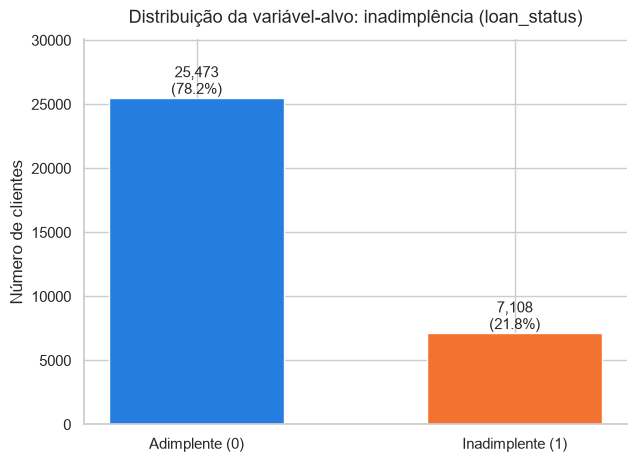

Razão de desbalanceamento: 3.6 adimplentes para cada inadimplente


In [ ]:
# ============================================================
# Gráfico 1: proporção de adimplentes x inadimplentes
# ============================================================

contagem_alvo = df[ALVO].value_counts().sort_index()                 # contagem absoluta (0, 1)
percentual_alvo = df[ALVO].value_counts(normalize=True).sort_index() * 100  # proporção (%)

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(
    ["Adimplente (0)", "Inadimplente (1)"],
    contagem_alvo.tolist(),
    color=[COR_ADIMPLENTE, COR_INADIMPLENTE],
    width=0.55,
)

# Rótulo com quantidade e percentual em cima de cada barra
for barra, qtd, pct in zip(barras, contagem_alvo.tolist(), percentual_alvo.tolist()):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
            f"{qtd:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=11)

ax.set_title("Distribuição da variável-alvo: inadimplência (loan_status)", fontsize=13, pad=12)
ax.set_ylabel("Número de clientes")
ax.set_ylim(0, contagem_alvo.max() * 1.18)   # folga no topo para os rótulos
sns.despine()                                  # remove bordas superior e direita (visual mais limpo)

fig.savefig(PASTA_FIGURAS / "01_desbalanceamento_alvo.png", bbox_inches="tight")
plt.show()

# Razão de desbalanceamento: quantos adimplentes existem para cada inadimplente
razao = contagem_alvo[0] / contagem_alvo[1]
print(f"Razão de desbalanceamento: {razao:.1f} adimplentes para cada inadimplente")

### Gráfico 2 — Distribuição das variáveis numéricas

As linhas verticais mostram a **média** (tracejada) e a **mediana** (contínua). Quanto mais distantes uma da outra, mais assimétrica é a distribuição. Para que a cauda de valores extremos não "esmague" o gráfico, o eixo é exibido até o **percentil 99**; a média e a mediana, porém, são calculadas com **todos** os dados. Os valores extremos são analisados com boxplots na Fase 2.

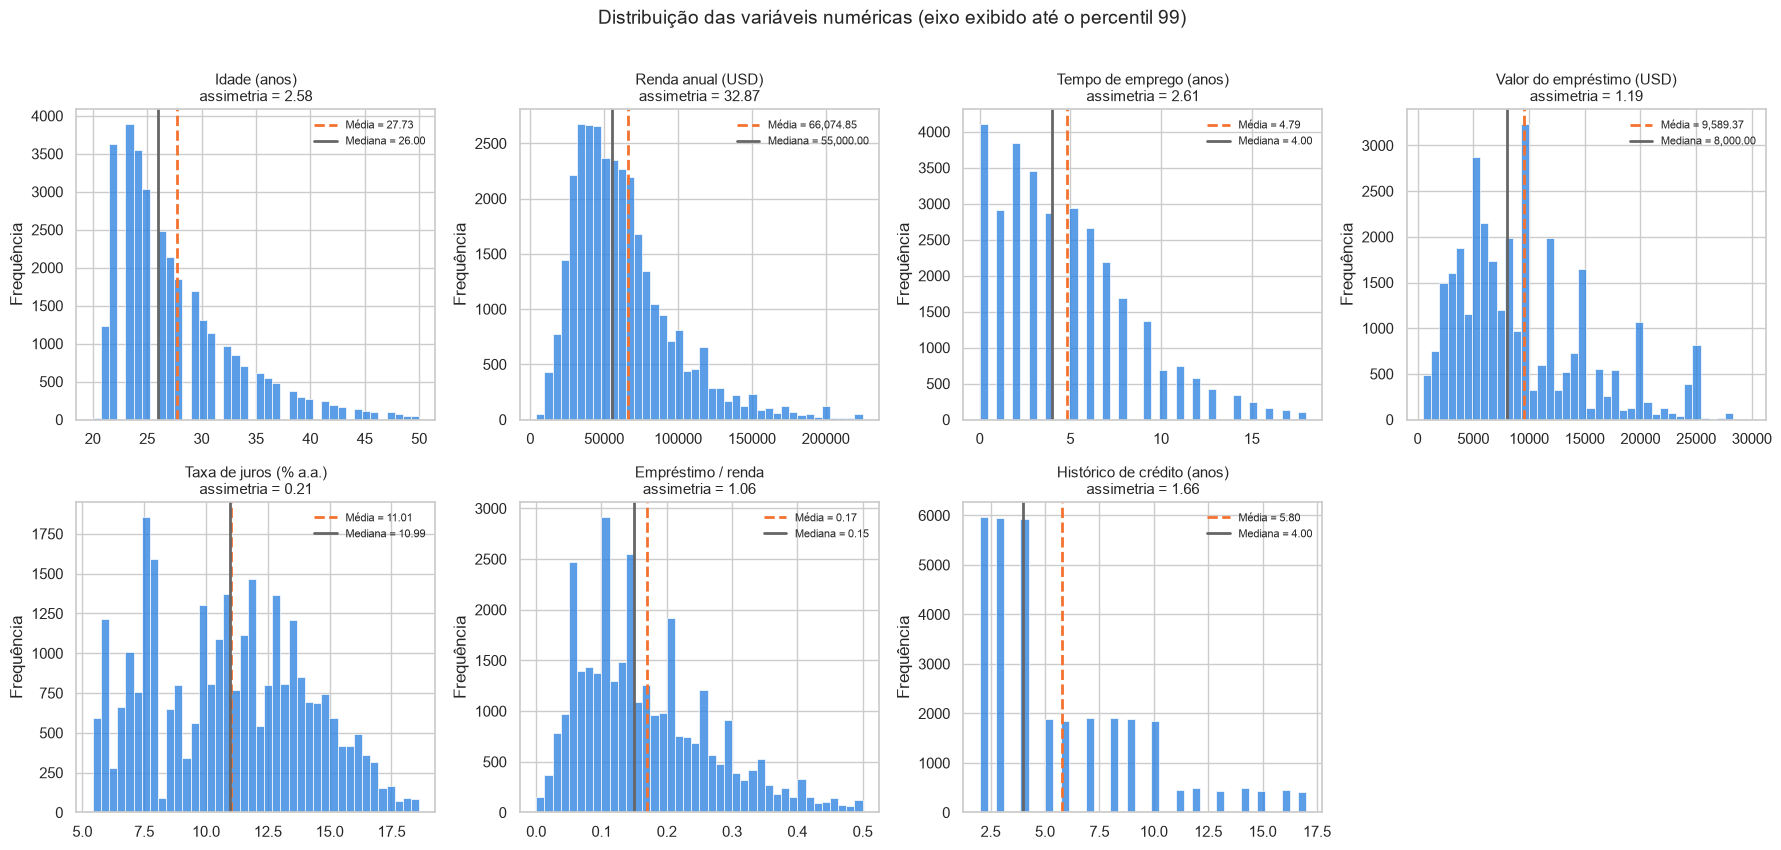

In [ ]:
# ============================================================
# Gráfico 2: histogramas das variáveis numéricas
# ============================================================

n_cols_grid = 4
n_linhas_grid = int(np.ceil(len(col_numericas) / n_cols_grid))
fig, axes = plt.subplots(n_linhas_grid, n_cols_grid, figsize=(18, 4.2 * n_linhas_grid))
axes = axes.flatten()   # transforma a grade 2D em lista para iterar facilmente

for ax, col in zip(axes, col_numericas):
    serie = df[col].dropna()               # ignora nulos só para desenhar
    limite_p99 = serie.quantile(0.99)      # corte visual no percentil 99
    sns.histplot(x=serie[serie <= limite_p99], bins=40, color=COR_ADIMPLENTE, ax=ax)

    # Média e mediana calculadas com TODOS os dados (sem o corte visual)
    ax.axvline(serie.mean(), color=COR_INADIMPLENTE, linestyle="--", linewidth=2, label=f"Média = {serie.mean():,.2f}")
    ax.axvline(serie.median(), color=COR_NEUTRA, linestyle="-", linewidth=2, label=f"Mediana = {serie.median():,.2f}")

    ax.set_title(f"{ROTULOS[col]}\nassimetria = {serie.skew():.2f}", fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("Frequência")
    ax.legend(fontsize=8, frameon=False)

# Esconde os quadros vazios da grade (quando o nº de variáveis não fecha a grade)
for ax in axes[len(col_numericas):]:
    ax.set_visible(False)

fig.suptitle("Distribuição das variáveis numéricas (eixo exibido até o percentil 99)", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "02_histogramas_numericas.png", bbox_inches="tight")
plt.show()

### Gráfico 3 — Mapa de calor da correlação de Pearson

A correlação de Pearson mede a **relação linear** entre duas variáveis numéricas (de −1 a +1). O alvo foi incluído para identificar quais variáveis se associam mais à inadimplência. Também serve para detectar **redundância** entre preditoras (correlação muito alta entre duas delas), o que afeta especialmente o KNN, pois uma mesma informação passa a contar duas vezes no cálculo da distância.

Só a metade inferior é exibida, pois a matriz é simétrica.

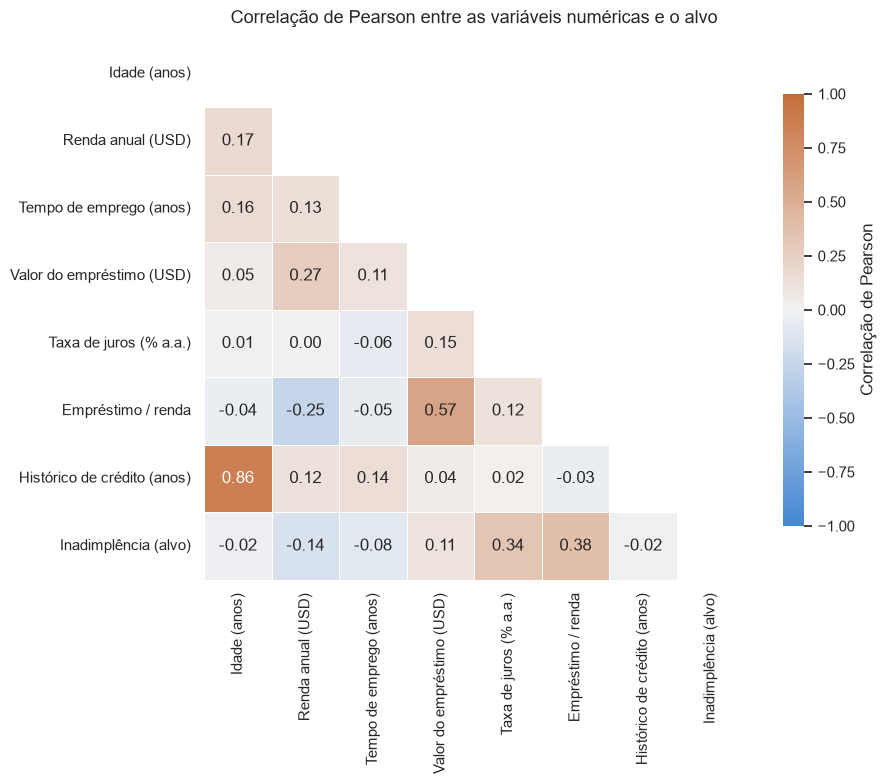

Correlação de cada variável com loan_status:
Empréstimo / renda (loan_percent_income)                    0.38
Taxa de juros (% a.a.) (loan_int_rate)                      0.34
Renda anual (USD) (person_income)                          -0.14
Valor do empréstimo (USD) (loan_amnt)                       0.10
Tempo de emprego (anos) (person_emp_length)                -0.08
Idade (anos) (person_age)                                  -0.02
Histórico de crédito (anos) (cb_person_cred_hist_length)   -0.02


In [ ]:
# ============================================================
# Gráfico 3: mapa de calor da correlação de Pearson
# ============================================================

matriz_corr = df[col_numericas + [ALVO]].corr(method="pearson")

# Versão com nomes em português, só para exibição no gráfico
matriz_corr_pt = matriz_corr.rename(index=ROTULOS, columns=ROTULOS)

# Máscara para esconder o triângulo superior (informação repetida)
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

# Paleta divergente: azul (correlação negativa) -> claro (zero) -> laranja (positiva)
paleta_divergente = sns.diverging_palette(250, 30, s=80, l=55, center="light", as_cmap=True)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    matriz_corr_pt, mask=mascara, cmap=paleta_divergente,
    vmin=-1, vmax=1, center=0,          # escala simétrica centrada no zero
    annot=True, fmt=".2f",              # mostra o valor de cada correlação
    linewidths=0.5, square=True,
    cbar_kws={"shrink": 0.8, "label": "Correlação de Pearson"}, ax=ax,
)
ax.set_title("Correlação de Pearson entre as variáveis numéricas e o alvo", fontsize=13, pad=12)
ax.grid(False)   # remove a grade de fundo, que atravessaria o triângulo vazio
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "03_heatmap_correlacao.png", bbox_inches="tight")
plt.show()

# Ranking das correlações com o alvo (da mais forte para a mais fraca, em módulo)
corr_alvo = matriz_corr[ALVO].drop(ALVO).sort_values(key=abs, ascending=False)
print("Correlação de cada variável com loan_status:")
corr_alvo = corr_alvo.rename(index=lambda c: f"{ROTULOS[str(c)]} ({c})")
print(corr_alvo.round(3).to_string())

### Gráfico 4 — Taxa de inadimplência por variável categórica

Gráfico complementar. A correlação de Pearson só se aplica a variáveis numéricas, então este gráfico mostra a relação das **categóricas** com o alvo: a proporção de inadimplentes em cada categoria. A linha tracejada marca a taxa média da base; barras acima dela indicam grupos de maior risco.

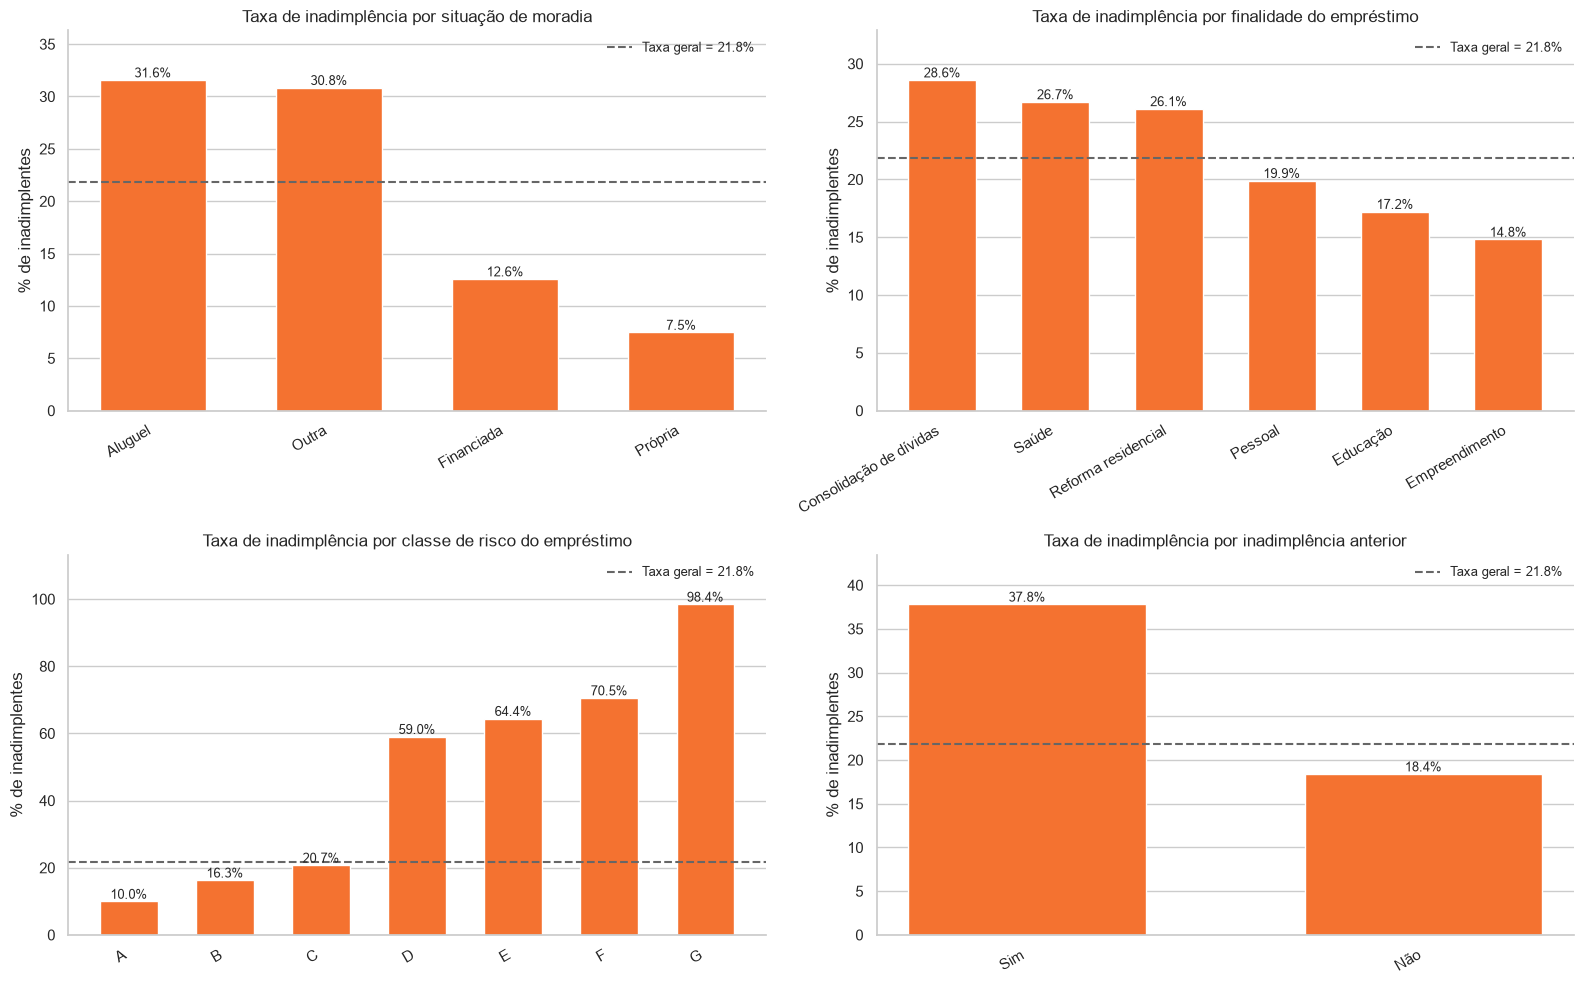

In [ ]:
# ============================================================
# Gráfico 4: taxa de inadimplência (%) por categoria
# ============================================================

taxa_geral = df[ALVO].mean() * 100   # taxa média de inadimplência da base inteira

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, col in zip(axes, col_categoricas):
    # Média do alvo por categoria = proporção de inadimplentes no grupo
    taxa = df.groupby(col)[ALVO].mean().mul(100)

    # loan_grade é ORDINAL (A < B < ... < G): mantém a ordem natural das classes.
    # As demais são ordenadas da maior para a menor taxa, para facilitar a leitura.
    taxa = taxa.sort_index() if col == "loan_grade" else taxa.sort_values(ascending=False)

    rotulos_x = [traduz_categoria(col, str(v)) for v in taxa.index]   # categorias em português
    barras = ax.bar(rotulos_x, taxa.tolist(), color=COR_INADIMPLENTE, width=0.6)
    ax.axhline(taxa_geral, color=COR_NEUTRA, linestyle="--", linewidth=1.5,
               label=f"Taxa geral = {taxa_geral:.1f}%")

    # Rótulo percentual em cada barra
    for barra, valor in zip(barras, taxa.tolist()):
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
                f"{valor:.1f}%", ha="center", va="bottom", fontsize=9)

    ax.set_title(f"Taxa de inadimplência por {ROTULOS[col].lower()}", fontsize=12)
    ax.set_ylabel("% de inadimplentes")
    ax.set_ylim(0, taxa.max() * 1.15)
    ax.tick_params(axis="x", rotation=30)
    plt.setp(ax.get_xticklabels(), ha="right")   # alinha rótulos inclinados à barra
    ax.grid(axis="x", visible=False)   # remove linhas verticais que cortariam as barras
    ax.legend(frameon=False, fontsize=9)
    sns.despine(ax=ax)

fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "04_inadimplencia_por_categoria.png", bbox_inches="tight")
plt.show()

## 1.6 Interpretação analítica e estratégia de preparação

In [ ]:
# ============================================================
# 1.6a Resumo quantitativo dos achados (calculado, não digitado)
# ============================================================
# Os números abaixo são recalculados a cada execução, garantindo que
# a interpretação textual sempre corresponda aos dados.

print("RESUMO DA EDA")
print("=" * 60)
print(f"Registros: {len(df):,} | Variáveis: {df.shape[1]}")
print(f"Desbalanceamento: {percentual_alvo[0]:.1f}% adimplentes x {percentual_alvo[1]:.1f}% inadimplentes "
      f"({razao:.1f} : 1)")
print(f"Linhas duplicadas: {n_duplicadas:,}")
for col, qtd in nulos.items():
    print(f"Nulos em {ROTULOS[str(col)]}: {qtd:,} ({qtd / len(df):.2%}) | assimetria = {df[col].skew():.2f}")
print(f"Idade > 100 anos: {idade_impossivel} | Tempo de emprego > idade: {emprego_impossivel}")
print(f"Maior assimetria: {ROTULOS[str(descritiva_num['assimetria'].idxmax())]} "
      f"({descritiva_num['assimetria'].max():.2f})")
print(f"Correlação idade x histórico de crédito: "
      f"{matriz_corr.loc['person_age', 'cb_person_cred_hist_length']:.2f}")

RESUMO DA EDA
Registros: 32,581 | Variáveis: 12
Desbalanceamento: 78.2% adimplentes x 21.8% inadimplentes (3.6 : 1)
Linhas duplicadas: 165
Nulos em Tempo de emprego (anos): 895 (2.75%) | assimetria = 2.61
Nulos em Taxa de juros (% a.a.): 3,116 (9.56%) | assimetria = 0.21
Idade > 100 anos: 5 | Tempo de emprego > idade: 2
Maior assimetria: Renda anual (USD) (32.87)
Correlação idade x histórico de crédito: 0.86


### 1.6b Interpretação

A base reúne **32.581 clientes e 12 variáveis**, e a variável-alvo é **desbalanceada: 78,2% de adimplentes contra 21,8% de inadimplentes (cerca de 3,6 : 1)**. Isso significa que um modelo que respondesse "adimplente" para todos os clientes atingiria 78% de acurácia sem identificar um único mau pagador; por isso, a acurácia isolada é enganosa, o balanceamento (SMOTE) será aplicado **somente no treino** e os modelos serão avaliados principalmente pelo **recall e F1 da classe 1**. Há valores nulos em apenas duas colunas, e o formato de cada distribuição define a imputação: o **tempo de emprego** (895 nulos; 2,75%) é fortemente assimétrico (2,61) e contém valores impossíveis, o que indica a **mediana**; a **taxa de juros** (3.116 nulos; 9,56%) é praticamente simétrica (0,21; média de 11,01 ≈ mediana de 10,99), o que torna a **média** adequada. Renda (assimetria de 32,87), idade (2,58) e tempo de emprego exibem **outliers severos**, incluindo registros logicamente impossíveis (idade acima de 100 anos e tempo de emprego maior que a idade). Como o KNN mede distâncias euclidianas e o `StandardScaler` depende da média e do desvio-padrão, ambos distorcidos por extremos, esses valores serão tratados na Fase 2 **antes** do escalonamento; a Árvore de Decisão, que decide por cortes de limiar, é robusta a eles. Entre as numéricas, as maiores correlações com a inadimplência são **empréstimo/renda (+0,38)** e **taxa de juros (+0,34)**, e a renda atua no sentido oposto (−0,14). As correlações lineares são apenas moderadas, o que sugere relações não lineares que a árvore tende a capturar melhor. Foram identificadas duas **redundâncias**: idade × histórico de crédito (0,86) e a futura coluna `comprometimento_renda`, que reproduz `loan_percent_income × 100` e será tratada na Fase 3 para não contar duas vezes no cálculo de distância do KNN. Nas categóricas, a **classe de risco** é o preditor mais forte, com inadimplência crescente de A (10,0%) a G (98,4%); clientes que moram de **aluguel** (31,6%) e que têm **inadimplência anterior** (37,8% contra 18,4%) apresentam risco bem acima da média de 21,8%, enquanto a **casa própria** (7,5%) indica baixo risco. Uma ressalva: a classe de risco é atribuída pelo próprio banco a partir de sua análise prévia, portanto parte do desempenho dos modelos refletirá essa avaliação já existente.

### Estratégia definida para as próximas fases

| Achado da EDA | Decisão | Fase |
|---|---|---|
| Linhas duplicadas | Remover | 2 |
| Nulos em tempo de emprego (assimétrico) | Imputar pela **mediana** | 2 |
| Nulos em taxa de juros (simétrico) | Imputar pela **média** | 2 |
| Idade > 100 e emprego > idade | Remover (erro de cadastro) | 2 |
| Renda com cauda extrema | Analisar via boxplot e limitar extremos (*clipping*) | 2 |
| `comprometimento_renda` duplica `loan_percent_income` | Criar a coluna exigida e remover a redundante | 3 |
| Alvo desbalanceado (3,6 : 1) | SMOTE **somente no treino** | 4 |
| Escalas muito diferentes (renda × taxa) | `StandardScaler` **somente para o KNN** | 4 |
| Acurácia enganosa | Priorizar recall e F1 da classe 1 | 5 e 6 |

---
# Fase 2 — Tratamento e Limpeza dos Dados (Data Prep)

Esta fase executa as decisões definidas na tabela de estratégia da Fase 1, **nesta ordem**:

1. **Duplicados** → remover.
2. **Valores impossíveis** → remover. Vem *antes* da imputação para que valores como 123 anos de emprego não contaminem a média e a mediana usadas para preencher os nulos.
3. **Nulos** → imputar, com a técnica escolhida conforme a distribuição de cada coluna.
4. **Outliers** → diagnosticar com boxplots e tratar considerando o impacto no KNN e na Árvore.

> **Nota metodológica sobre vazamento de dados.** A mediana, a média e o percentil usados aqui são calculados sobre a base inteira, antes da divisão treino/teste, seguindo a ordem de fases do enunciado. Em um pipeline de produção, essas estatísticas seriam calculadas **apenas no treino** (por exemplo, com `SimpleImputer` dentro de um `Pipeline`). Com 32 mil registros, o efeito prático é desprezível (as estatísticas quase não mudam entre amostras), mas a limitação fica registrada. Já o balanceamento e o escalonamento, que têm impacto real de vazamento, serão feitos estritamente no treino na Fase 4.

In [17]:
# Guarda o tamanho inicial para o resumo final desta fase
n_linhas_inicial = len(df)
print(f"Registros no início da Fase 2: {n_linhas_inicial:,}")

Registros no início da Fase 2: 32,581


## 2.1 Remoção de linhas duplicadas

**Justificativa:** linhas idênticas em todas as colunas não acrescentam informação e causam dois problemas: (1) dão peso artificial a certos perfis de cliente durante o treino; (2) após o split, uma cópia pode cair no treino e outra no teste, de modo que o modelo é avaliado em um registro que ele já viu, o que **infla as métricas** de forma enganosa.

In [ ]:
# ============================================================
# 2.1 Duplicados
# ============================================================

n_antes = len(df)

# drop_duplicates() mantém a primeira ocorrência e remove as repetições.
# reset_index(drop=True) renumera o índice de 0 a n-1, sem buracos.
df = df.drop_duplicates().reset_index(drop=True)

n_removidas_duplicadas = n_antes - len(df)
print(f"Duplicadas removidas: {n_removidas_duplicadas:,}")
print(f"Registros restantes:  {len(df):,}")
print(f"Duplicadas após a limpeza: {df.duplicated().sum()}")   # deve ser 0

Duplicadas removidas: 165
Registros restantes:  32,416
Duplicadas após a limpeza: 0


## 2.2 Remoção de registros logicamente impossíveis

**Justificativa:** idade acima de 100 anos para um tomador de crédito e tempo de emprego maior que a própria idade são **erros de cadastro**, não clientes reais com perfil extremo. Como são poucos registros, removê-los não altera a representatividade da base, enquanto mantê-los distorceria as distâncias do KNN e as estatísticas usadas na imputação.

Registros com tempo de emprego **nulo** não são afetados por este filtro (a comparação com nulo resulta em falso); eles serão imputados na etapa seguinte.

In [ ]:
# ============================================================
# 2.2 Valores impossíveis
# ============================================================

# Máscara booleana: True nas linhas com erro de cadastro
mascara_impossivel = (
    (df["person_age"] > 100)                              # idade implausível
    | (df["person_emp_length"] > df["person_age"])        # emprego maior que a idade
)

print(f"Registros impossíveis encontrados: {mascara_impossivel.sum()}")
display(df.loc[mascara_impossivel, ["person_age", "person_emp_length", "person_income", "loan_status"]]
          .rename(columns=ROTULOS))

# Mantém apenas as linhas válidas (~ inverte a máscara)
df = df.loc[~mascara_impossivel].reset_index(drop=True)
n_removidas_impossiveis = int(mascara_impossivel.sum())
print(f"Registros restantes: {len(df):,}")

Registros impossíveis encontrados: 7


,Idade (anos),Tempo de emprego (anos),Renda anual (USD),Inadimplência (alvo)
0,22,123.00,59000,1
81,144,4.00,250000,0
183,144,4.00,200000,0
210,21,123.00,192000,0
575,123,2.00,80004,0
747,123,7.00,78000,0
32132,144,12.00,6000000,0


Registros restantes: 32,409


## 2.3 Tratamento de valores nulos

**Critério de escolha:**
- **Média:** indicada para distribuições **simétricas**, nas quais ela representa bem o centro dos dados.
- **Mediana:** indicada para distribuições **assimétricas** ou com outliers, pois não é "puxada" pelos valores extremos.

A tabela abaixo é recalculada **após** a remoção dos registros impossíveis e sustenta a decisão de cada coluna.

In [ ]:
# ============================================================
# 2.3a Evidência estatística para escolher média x mediana
# ============================================================

colunas_com_nulos = df.columns[df.isna().any()].tolist()

evidencia_imputacao = pd.DataFrame({
    "descrição": [ROTULOS[c] for c in colunas_com_nulos],
    "nulos": df[colunas_com_nulos].isna().sum().values,
    "%_nulos": (df[colunas_com_nulos].isna().mean() * 100).round(2).values,
    "média": df[colunas_com_nulos].mean().values,
    "mediana": df[colunas_com_nulos].median().values,
    "assimetria": df[colunas_com_nulos].skew().values,
}, index=colunas_com_nulos)

evidencia_imputacao

,descrição,nulos,%_nulos,média,mediana,assimetria
person_emp_length,Tempo de emprego (anos),887,2.74,4.78,4.00,1.25
loan_int_rate,Taxa de juros (% a.a.),3094,9.55,11.02,10.99,0.21


**Decisões:**

- **Tempo de emprego → mediana.** A distribuição tem cauda longa à direita (assimetria positiva e média acima da mediana): poucos clientes com muitos anos de emprego "puxam" a média para cima. A mediana representa melhor o cliente típico.

- **Taxa de juros → média por classe de risco.** A distribuição é praticamente simétrica (média ≈ mediana), então a **média** é a medida adequada. Porém, a taxa de juros é **definida a partir da classe de risco** do empréstimo (A, B, ..., G): um empréstimo classe A tem juros muito menores que um classe G. Preencher todos os nulos com uma única média global atribuiria juros de "classe média" a um empréstimo de classe A ou G. Por isso, cada nulo recebe a **média da sua própria classe de risco**, o que preserva a relação entre as duas variáveis. A tabela a seguir comprova essa dependência.

In [ ]:
# ============================================================
# 2.3b Comprovação: a taxa de juros depende da classe de risco
# ============================================================

juros_por_classe = (
    df.groupby("loan_grade")["loan_int_rate"]
      .agg(media="mean", mediana="median", desvio_padrao="std", nulos=lambda s: s.isna().sum())
)
display(juros_por_classe)

print(f"Média global da taxa de juros:         {df['loan_int_rate'].mean():.2f}%")
print(f"Desvio-padrão global:                  {df['loan_int_rate'].std():.2f}")
print(f"Desvio-padrão médio DENTRO das classes: {juros_por_classe['desvio_padrao'].mean():.2f}")
reducao = 1 - juros_por_classe["desvio_padrao"].mean() / df["loan_int_rate"].std()
print(f"-> Conhecer a classe reduz a dispersão da taxa de juros em {reducao:.0%}: "
      "a média da classe é uma estimativa mais precisa que a média global.")

,media,mediana,desvio_padrao,nulos
loan_grade,,,,
A,7.33,7.49,1.04,990
B,11.00,10.99,0.91,1049
C,13.46,13.48,0.96,629
D,15.36,15.31,1.11,311
E,17.01,16.82,1.32,83
F,18.61,18.54,1.38,27
G,20.25,20.16,1.07,5


Média global da taxa de juros:         11.02%
Desvio-padrão global:                  3.24
Desvio-padrão médio DENTRO das classes: 1.11
-> Conhecer a classe reduz a dispersão da taxa de juros em 66%: a média da classe é uma estimativa mais precisa que a média global.


In [ ]:
# ============================================================
# 2.3c Imputação
# ============================================================

# Tempo de emprego: mediana (distribuição assimétrica)
mediana_emprego = df["person_emp_length"].median()
df["person_emp_length"] = df["person_emp_length"].fillna(mediana_emprego)

# Taxa de juros: média da classe de risco de cada empréstimo.
# .map() troca cada classe (A, B, ...) pela média de juros daquela classe;
# .fillna() usa esse valor apenas onde a taxa está ausente.
media_juros_por_classe = df.groupby("loan_grade")["loan_int_rate"].mean()
df["loan_int_rate"] = df["loan_int_rate"].fillna(df["loan_grade"].map(media_juros_por_classe))

print(f"Tempo de emprego: nulos preenchidos com a mediana = {mediana_emprego:.1f} anos")
print("Taxa de juros: nulos preenchidos com a média da classe de risco:")
print(media_juros_por_classe.round(2).to_string())
print(f"\nTotal de nulos restantes na base: {df.isna().sum().sum()}")   # deve ser 0

Tempo de emprego: nulos preenchidos com a mediana = 4.0 anos
Taxa de juros: nulos preenchidos com a média da classe de risco:
loan_grade
A    7.33
B   11.00
C   13.46
D   15.36
E   17.01
F   18.61
G   20.25

Total de nulos restantes na base: 0


## 2.4 Análise e tratamento de outliers

**Por que o tratamento importa de forma diferente para cada modelo:**

- **KNN — muito sensível.** Classifica pela distância euclidiana aos vizinhos. Um valor extremo domina essa distância e, além disso, distorce a média e o desvio-padrão usados pelo `StandardScaler`, comprimindo todos os clientes "normais" em uma faixa estreita da escala.
- **Árvore de Decisão — robusta.** Decide por cortes do tipo "renda > 50 mil?". Um cliente com renda de 6 milhões cai do mesmo lado do corte que um de 60 mil, sem alterar a regra. Valores extremos não deslocam os limiares.

O critério de detecção é o **intervalo interquartil (IQR)**: são considerados outliers os valores abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR.

In [ ]:
# ============================================================
# 2.4a Contagem de outliers pelo critério IQR
# ============================================================

def resumo_outliers_iqr(serie: pd.Series) -> dict:
    """Calcula limites do IQR e quantos valores ficam fora deles."""
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fora = (serie < lim_inf) | (serie > lim_sup)
    return {"descrição": ROTULOS[str(serie.name)], "outliers": int(fora.sum()),
            "%_outliers": round(fora.mean() * 100, 2), "limite_superior_IQR": lim_sup,
            "máximo": serie.max()}

tabela_outliers = pd.DataFrame([resumo_outliers_iqr(df[c]) for c in col_numericas], index=col_numericas)
tabela_outliers.sort_values("%_outliers", ascending=False)

,descrição,outliers,%_outliers,limite_superior_IQR,máximo
loan_amnt,Valor do empréstimo (USD),1678,5.18,23125.00,35000.00
person_age,Idade (anos),1486,4.59,40.50,94.00
person_income,Renda anual (USD),1474,4.55,140250.00,2039784.00
cb_person_cred_hist_length,Histórico de crédito (anos),1138,3.51,15.50,30.00
person_emp_length,Tempo de emprego (anos),850,2.62,14.50,41.00
loan_percent_income,Empréstimo / renda,649,2.00,0.44,0.83
loan_int_rate,Taxa de juros (% a.a.),6,0.02,21.84,23.22


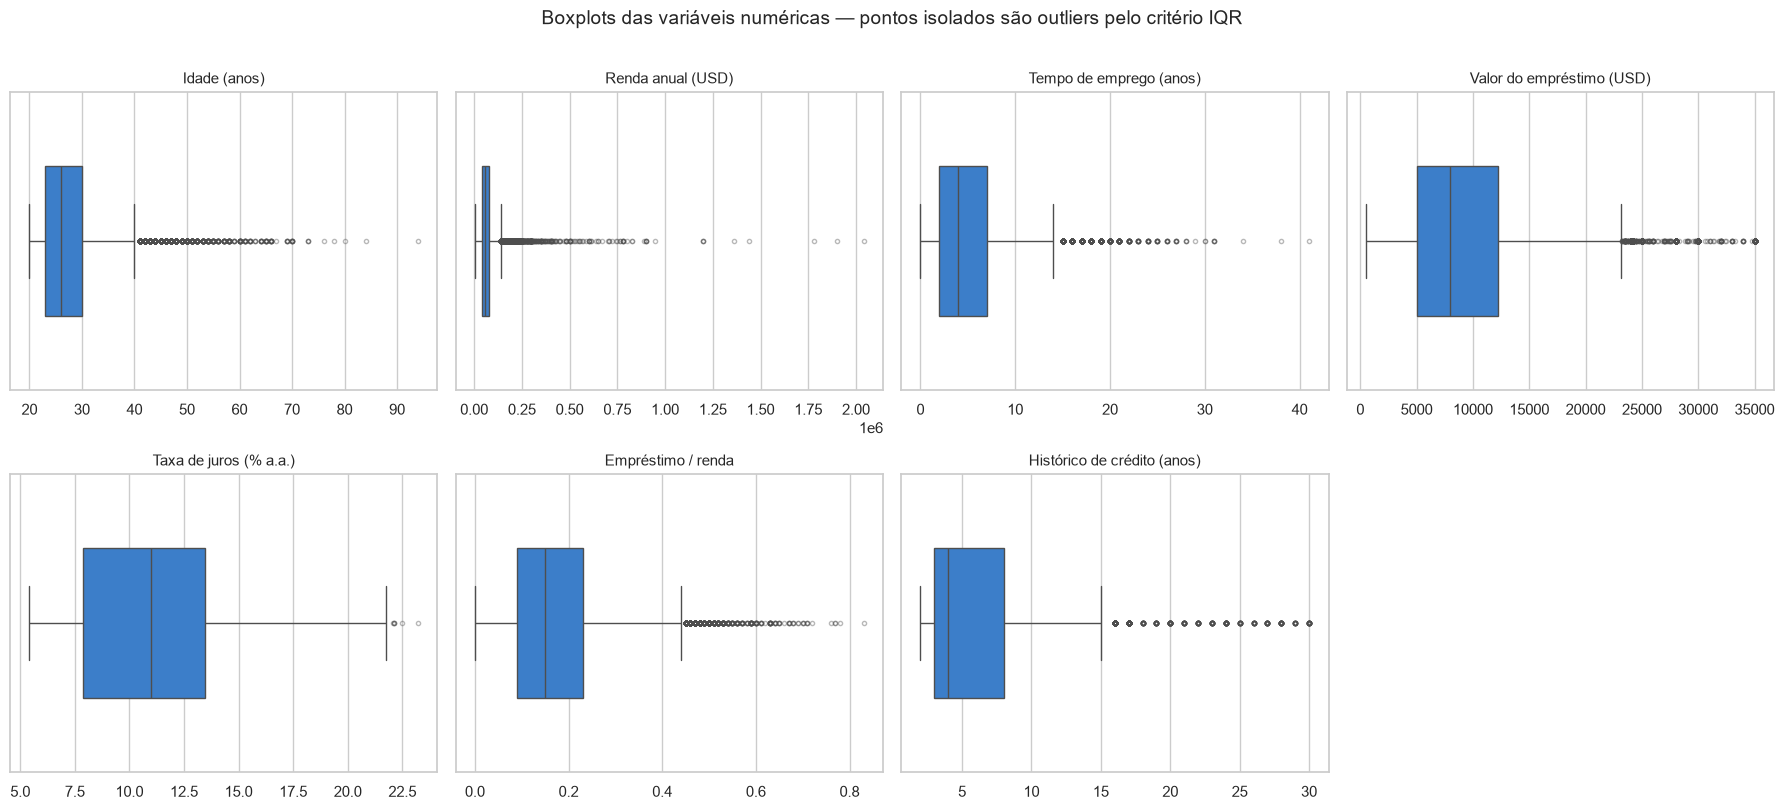

In [ ]:
# ============================================================
# 2.4b Boxplots das variáveis numéricas (antes do tratamento)
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, col in zip(axes, col_numericas):
    sns.boxplot(x=df[col], color=COR_ADIMPLENTE, width=0.5, ax=ax,
                flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
    ax.set_title(ROTULOS[col], fontsize=11)
    ax.set_xlabel("")

for ax in axes[len(col_numericas):]:
    ax.set_visible(False)

fig.suptitle("Boxplots das variáveis numéricas — pontos isolados são outliers pelo critério IQR",
             fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "05_boxplots_outliers.png", bbox_inches="tight")
plt.show()

### Decisão de tratamento

O critério IQR aponta muitos "outliers", mas **outlier estatístico não é sinônimo de erro**. A decisão foi tomada variável por variável:

| Variável | Decisão | Justificativa |
|---|---|---|
| **Renda anual** | **Limitar no percentil 99** (*clipping*) | É a variável com cauda mais extrema. Rendas muito altas são reais (não são erros), então **remover** esses clientes descartaria informação legítima. O *clipping* mantém o cliente na base, preserva a ordem (ele continua entre os de maior renda) e impede que um único valor domine a distância do KNN e o `StandardScaler`. |
| Idade, tempo de emprego, histórico de crédito | Manter | Os erros de cadastro já foram removidos na etapa 2.2. Os valores restantes são plausíveis (clientes mais velhos ou com longa carreira). |
| Valor do empréstimo | Manter | O máximo (35 mil) é um teto de política de crédito, não um erro. |
| Taxa de juros, empréstimo/renda | Manter | Valores altos são justamente os sinais de risco que o modelo precisa aprender. |

O *clipping* é aplicado à base usada pelos dois modelos. Para a Árvore ele é praticamente neutro, pois a ordem dos valores é preservada e os cortes continuam válidos; para o KNN, ele é essencial.

In [ ]:
# ============================================================
# 2.4c Clipping da renda no percentil 99
# ============================================================

limite_renda_p99 = df["person_income"].quantile(0.99)
renda_antes = df["person_income"].copy()   # cópia para comparar antes x depois

# .clip(upper=...) substitui todo valor acima do limite pelo próprio limite
df["person_income"] = df["person_income"].clip(upper=limite_renda_p99)

n_rendas_limitadas = int((renda_antes > limite_renda_p99).sum())
print(f"Limite (percentil 99): USD {limite_renda_p99:,.0f}")
print(f"Clientes com renda limitada: {n_rendas_limitadas} ({n_rendas_limitadas / len(df):.2%})")
print(f"Renda máxima: antes USD {renda_antes.max():,.0f} -> depois USD {df['person_income'].max():,.0f}")
print(f"Assimetria da renda: antes {renda_antes.skew():.2f} -> depois {df['person_income'].skew():.2f}")

Limite (percentil 99): USD 225,000
Clientes com renda limitada: 322 (0.99%)
Renda máxima: antes USD 2,039,784 -> depois USD 225,000
Assimetria da renda: antes 9.78 -> depois 1.71


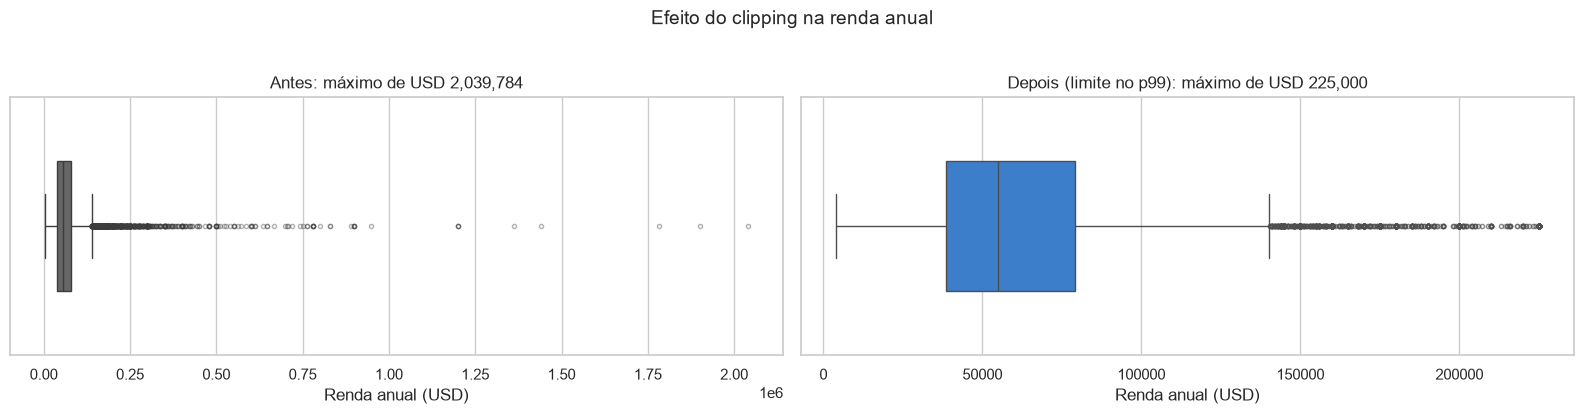

In [ ]:
# ============================================================
# 2.4d Comparação visual: renda antes x depois do clipping
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

sns.boxplot(x=renda_antes, color=COR_NEUTRA, width=0.5, ax=axes[0],
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
axes[0].set_title(f"Antes: máximo de USD {renda_antes.max():,.0f}", fontsize=12)

sns.boxplot(x=df["person_income"], color=COR_ADIMPLENTE, width=0.5, ax=axes[1],
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
axes[1].set_title(f"Depois (limite no p99): máximo de USD {df['person_income'].max():,.0f}", fontsize=12)

for ax in axes:
    ax.set_xlabel("Renda anual (USD)")

fig.suptitle("Efeito do clipping na renda anual", fontsize=14, y=1.03)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "06_renda_antes_depois_clipping.png", bbox_inches="tight")
plt.show()

## 2.5 Resumo da limpeza

In [ ]:
# ============================================================
# 2.5 Resumo da Fase 2
# ============================================================

print("RESUMO DO DATA PREP")
print("=" * 60)
print(f"Registros iniciais:               {n_linhas_inicial:,}")
print(f"(-) Duplicados removidos:         {n_removidas_duplicadas:,}")
print(f"(-) Registros impossíveis:        {n_removidas_impossiveis:,}")
print(f"(=) Registros finais:             {len(df):,}  "
      f"({len(df) / n_linhas_inicial:.2%} da base original)")
print(f"Nulos restantes:                  {df.isna().sum().sum()}")
print(f"Rendas limitadas no p99:          {n_rendas_limitadas:,}")
print(f"Proporção de inadimplentes:       {df[ALVO].mean():.2%}  (antes: {percentual_alvo[1]:.2f}%)")

RESUMO DO DATA PREP
Registros iniciais:               32,581
(-) Duplicados removidos:         165
(-) Registros impossíveis:        7
(=) Registros finais:             32,409  (99.47% da base original)
Nulos restantes:                  0
Rendas limitadas no p99:          322
Proporção de inadimplentes:       21.87%  (antes: 21.82%)
